In [21]:
!pip3 install xgboost


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: /Library/Frameworks/Python.framework/Versions/3.13/bin/python3.13 -m pip install --upgrade pip


In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os 

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler , LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("atharvaingle/crop-recommendation-dataset")
print("Path to dataset files:", path)

Path to dataset files: /Users/aayushkamble/.cache/kagglehub/datasets/atharvaingle/crop-recommendation-dataset/versions/1


In [5]:
files = os.listdir(path)
print("Files in dataset:", files)

csv_files = [f for f in files if f.endswith('.csv')]
if csv_files:
    for csv_file in csv_files:
        print(f"\n--- Displaying first few rows of {csv_file} ---")
        df = pd.read_csv(os.path.join(path, csv_file))
        display(df.head())
else:
    for f in files:
        full_path = os.path.join(path, f)
        if os.path.isdir(full_path):
            print(f"\nSubdirectory '{f}' contains:", os.listdir(full_path)[:10])

Files in dataset: ['Crop_recommendation.csv']

--- Displaying first few rows of Crop_recommendation.csv ---


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [6]:
file_path = os.path.join(path , 'Crop_recommendation.csv')
df = pd.read_csv(file_path)
df.head(10)

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice
5,69,37,42,23.058049,83.370118,7.073454,251.055000,rice
6,69,55,38,22.708838,82.639414,5.700806,271.324860,rice
7,94,53,40,20.277744,82.894086,5.718627,241.974195,rice
8,89,54,38,24.515881,83.535216,6.685346,230.446236,rice
9,68,58,38,23.223974,83.033227,6.336254,221.209196,rice


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [8]:
df.isnull().sum()

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
numerical_cols = [cols for cols in df.columns if df[cols].dtype != 'O']
categorical_cols = [cols for cols in df.columns if df[cols].dtype == 'O']

print('numerical_cols {} {}'.format(len(numerical_cols) , numerical_cols))
print('categorical_cols {} {}'.format(len(categorical_cols) , categorical_cols))


numerical_cols 7 ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
categorical_cols 1 ['label']


In [11]:
df['label'].unique()

array(['rice', 'maize', 'chickpea', 'kidneybeans', 'pigeonpeas',
       'mothbeans', 'mungbean', 'blackgram', 'lentil', 'pomegranate',
       'banana', 'mango', 'grapes', 'watermelon', 'muskmelon', 'apple',
       'orange', 'papaya', 'coconut', 'cotton', 'jute', 'coffee'],
      dtype=object)

In [12]:
encode = LabelEncoder()

df['Label_encoder'] = encode.fit_transform(df['label'])

df['Label_encoder'].unique()

    

array([20, 11,  3,  9, 18, 13, 14,  2, 10, 19,  1, 12,  7, 21, 15,  0, 16,
       17,  4,  6,  8,  5])

In [13]:
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label,Label_encoder
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice,20
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice,20
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice,20
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice,20
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice,20


In [14]:
df.drop(columns=['label'] , axis= 1 , inplace=True)

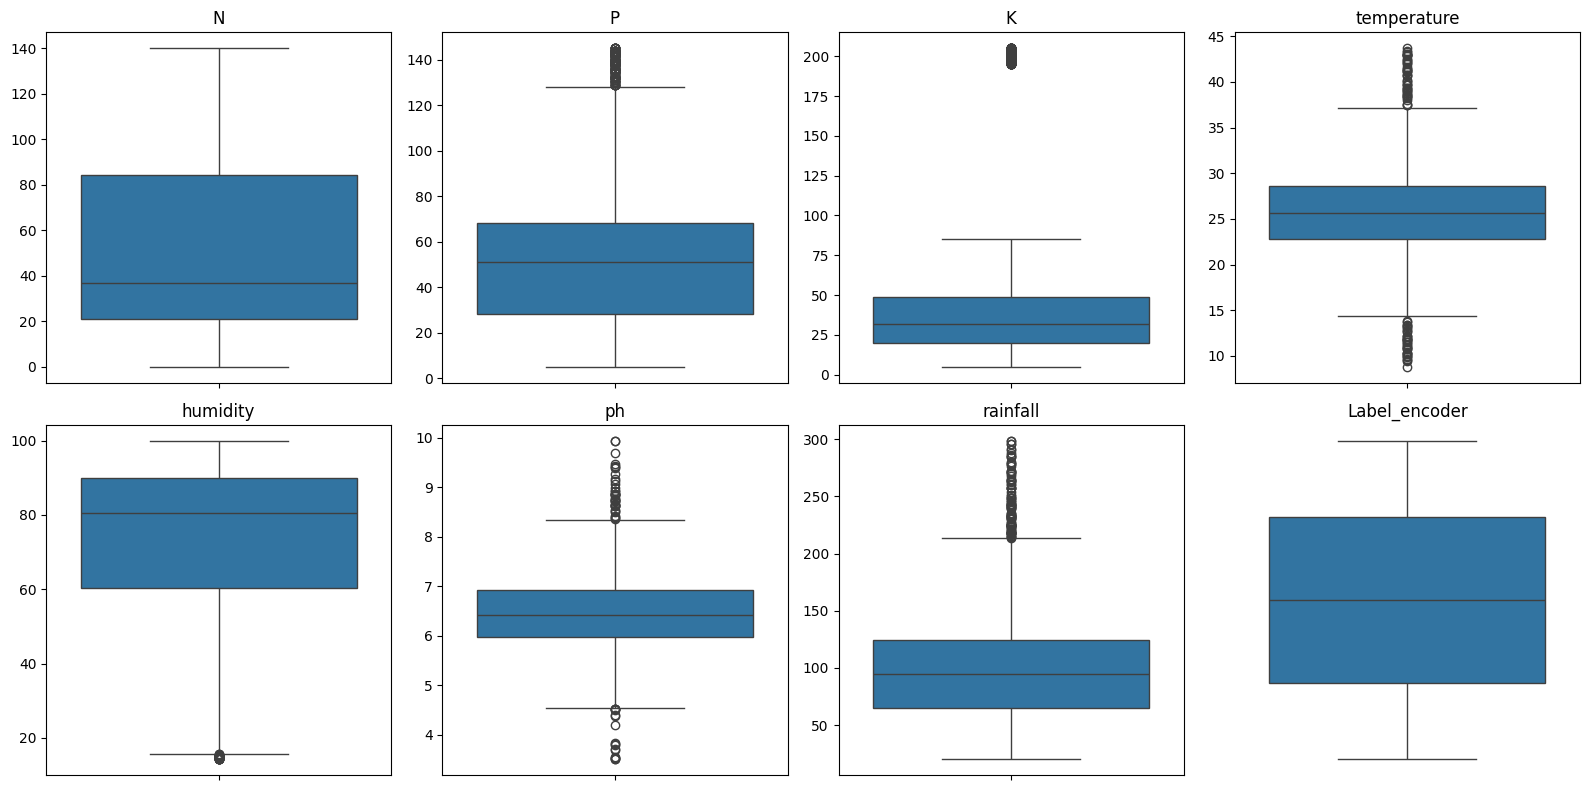

In [15]:
numeric_cols = df.select_dtypes(include='number').columns
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)     
    axes[i].set_ylabel('')      

axes[-1].axis('off')
plt.tight_layout()
plt.show()

In [16]:
Q1 = df['K'].quantile(0.25)
Q3 = df['K'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['K'] < lower_bound) | (df['K'] > upper_bound)]
print(f'{len(outliers)} outliers out of {len(df)} rows') 

200 outliers out of 2200 rows


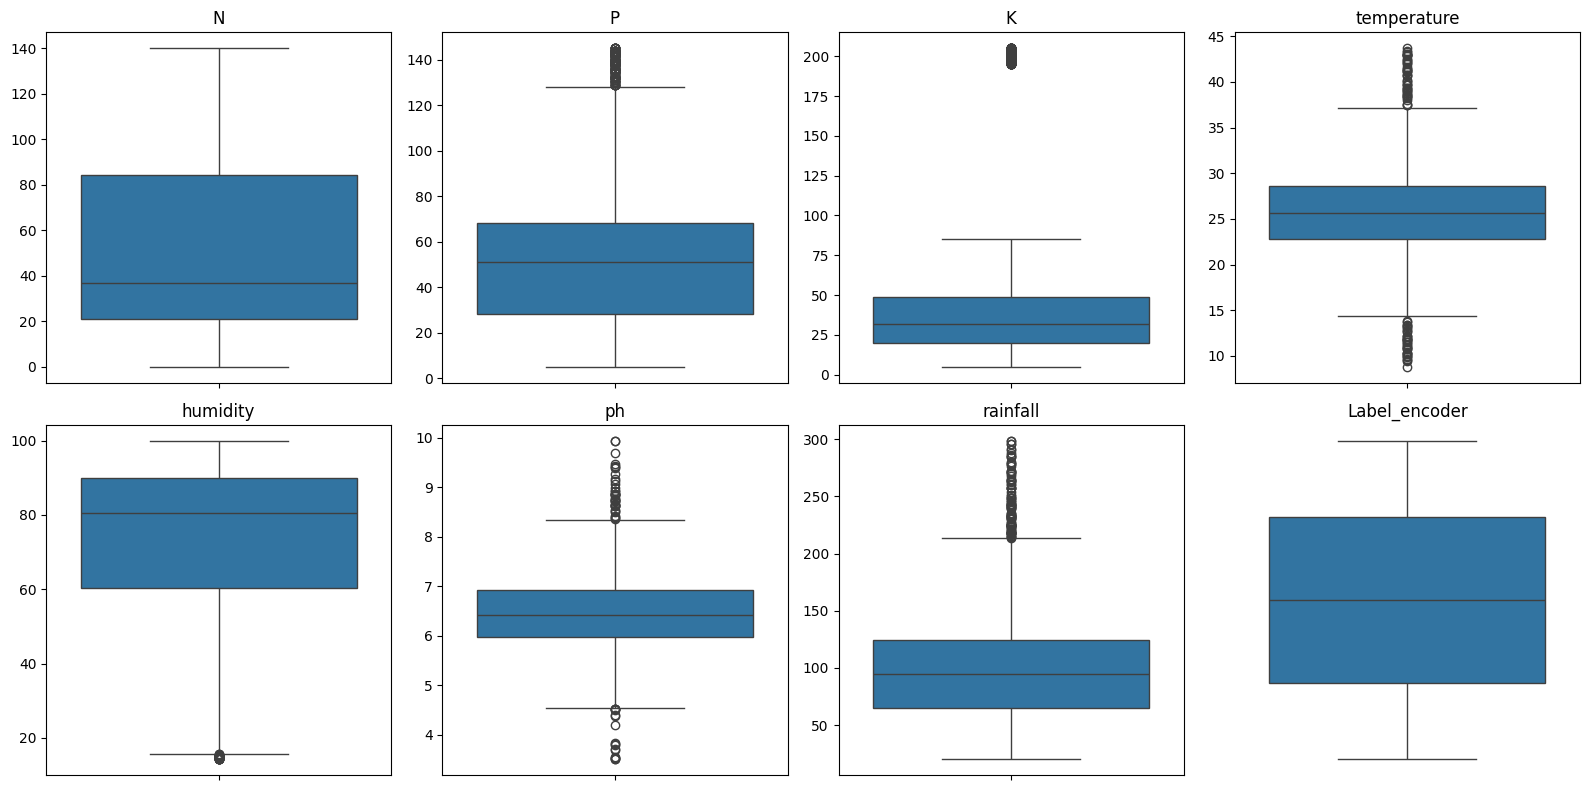

In [17]:
numeric_cols = df.select_dtypes(include='number').columns
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)     
    axes[i].set_ylabel('')      

axes[-1].axis('off')
plt.tight_layout()
plt.show()

In [28]:
import pickle
from asyncio import exceptions
X = df.drop(columns=['Label_encoder'])
y = df['Label_encoder']

X_train , X_test, y_train , y_test = train_test_split(X , y , test_size=0.2 , random_state=42)

scaling = StandardScaler()
X_train_scaled = scaling.fit_transform(X_train)
X_test_scaled = scaling.transform(X_test)


with open('scaler.pkl', 'wb') as file:
    pickle.dump(scaling, file)

In [39]:
models = {
    'Random Forest' : RandomForestClassifier(n_estimators=200 , random_state=42),
    'XGBoost' : XGBClassifier(random_state=42),
    'Logistic Regression': LogisticRegression(),
    'Decision Tree' : DecisionTreeClassifier(random_state=42),
}

params = {
    'Random Forest': {
        'n_estimators': [100, 200, 300],
        'max_depth': [None, 10, 20],
        'min_samples_split': [2, 5],
    },
    'XGBoost': {
        'n_estimators': [100, 200],
        'max_depth': [3, 6, 9],
        'learning_rate': [0.01, 0.1, 0.3],
    },
    'Logistic Regression': {
        'C': [0.01, 0.1, 1, 10],
        'solver': ['lbfgs', 'liblinear'],
    },
    'Decision Tree': {
        'max_depth': [None, 5, 10, 20],
        'min_samples_split': [2, 5, 10],
    },
}

In [42]:
from sklearn.model_selection import GridSearchCV
best_models = {}
for name, model in models.items():
    print(f"Tuning {name}...")
    grid = GridSearchCV(
        estimator=model,
        param_grid=params[name],
        cv=5,
        scoring='accuracy',
        n_jobs=-1
    )
    grid.fit(X_train_scaled, y_train)
    
    best_models[name] = {
        'best_estimator': grid.best_estimator_,
        'best_score': grid.best_score_,
        'best_params': grid.best_params_
    }
    print(f"{name} Best CV Score: {grid.best_score_:.4f}\n")

    with open("model.pkl" , 'wb') as file:
        pickle.dump(best_models , file)

Tuning Random Forest...
Random Forest Best CV Score: 0.9955

Tuning XGBoost...
XGBoost Best CV Score: 0.9903

Tuning Logistic Regression...
Logistic Regression Best CV Score: 0.9790

Tuning Decision Tree...
Decision Tree Best CV Score: 0.9864



In [41]:
grid.best_estimator_

DecisionTreeClassifier(min_samples_split=5, random_state=42)